STEP 1 – Data Loading & Cleaning

Merged dataset shape : (1007, 8)
Date range           : 2019-05-31 → 2020-10-31
States / UTs         : 28
Missing values :
Region                  0
Date                    0
Frequency               0
unemployment_rate       0
employed                0
labour_participation    0
Area                    0
period                  0
dtype: int64

Basic statistics:
       unemployment_rate     employed  labour_participation
count            1007.00      1007.00               1007.00
mean               11.91   8996209.18                 42.38
std                10.74  10207838.81                  8.05
min                 0.00     49420.00                 13.33
25%                 4.69   1639125.00                 37.84
50%                 8.89   5543380.00                 40.88
75%                16.12  12871154.00                 45.32
max                76.74  59433759.00                 72.57

✅ Saved fig1_national_trend.png
✅ Saved fig2_state_analysis.pn

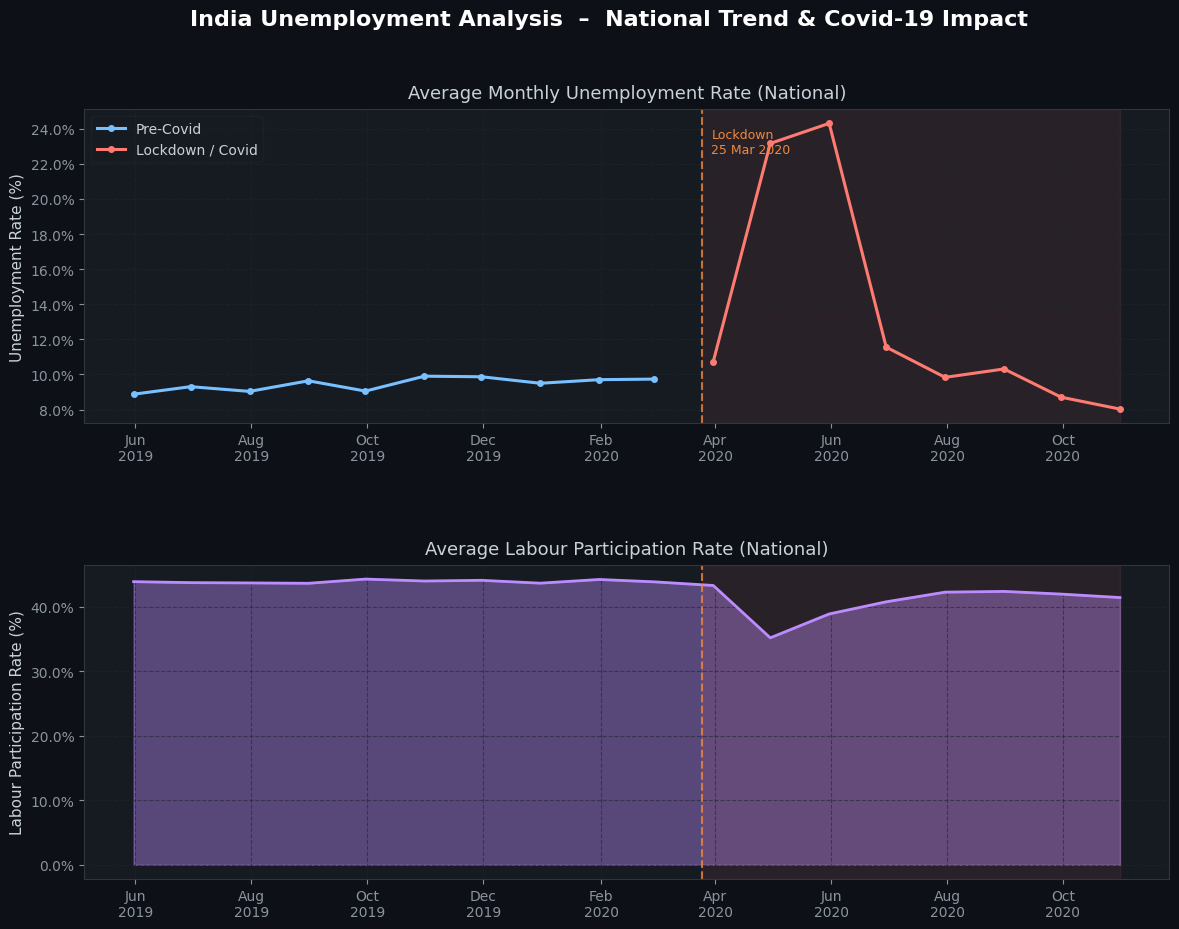

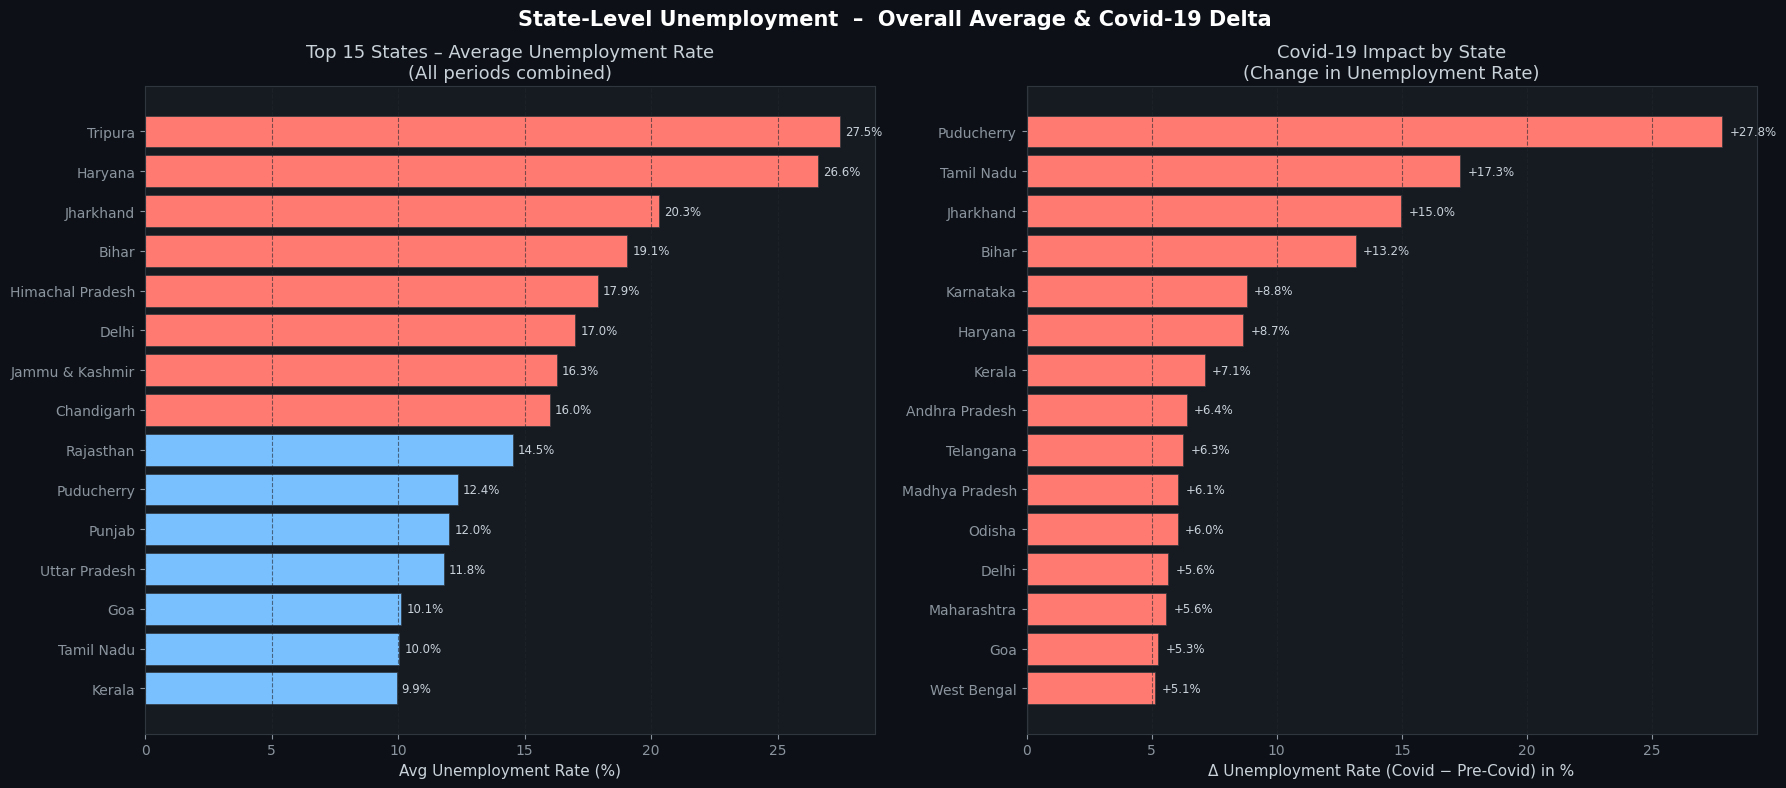

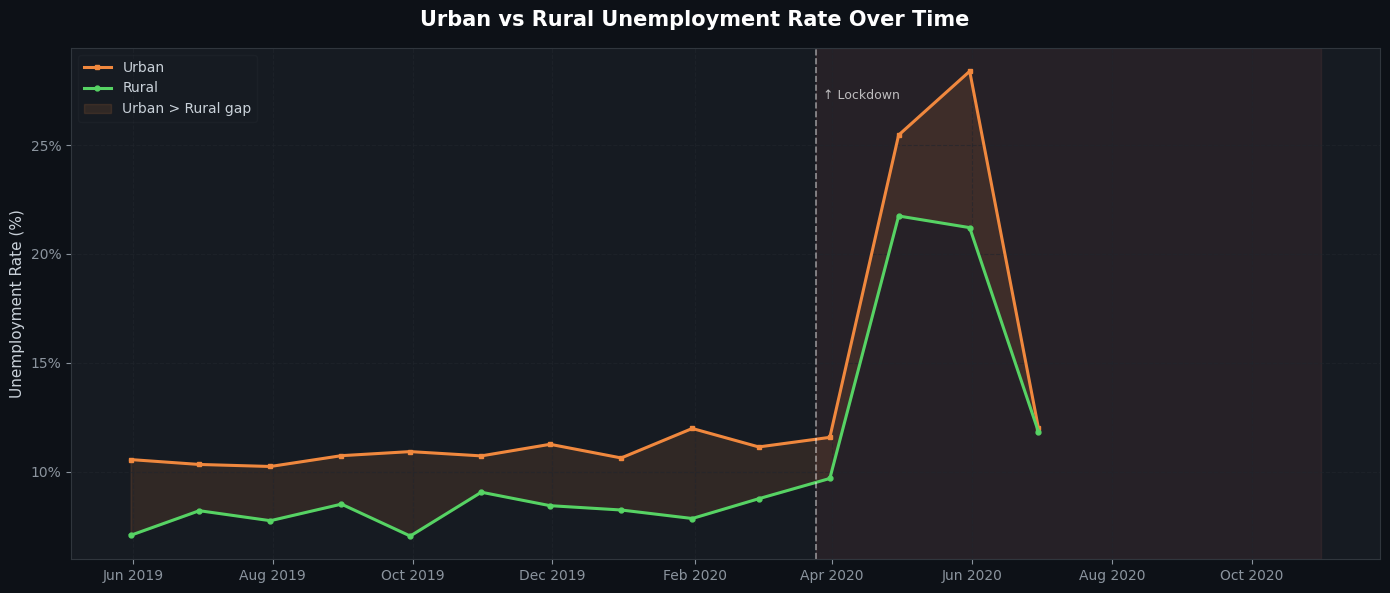

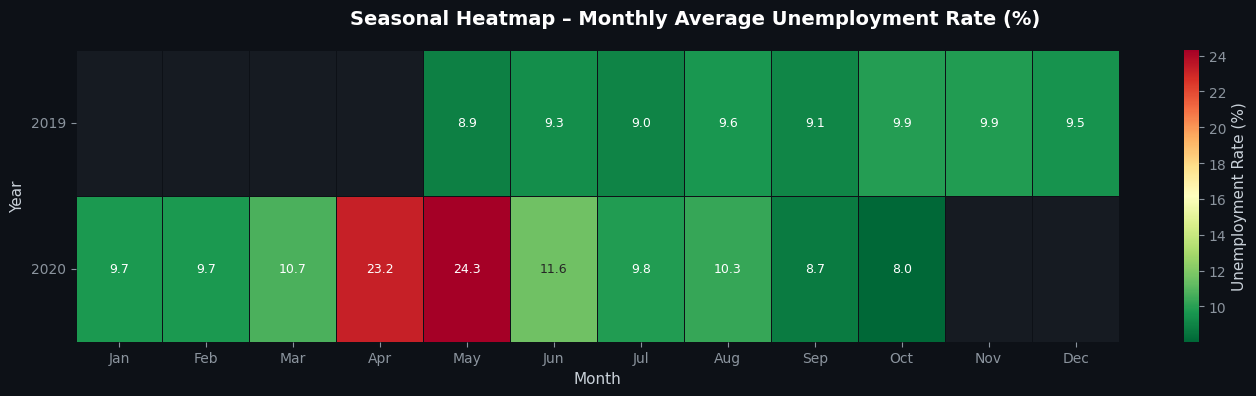

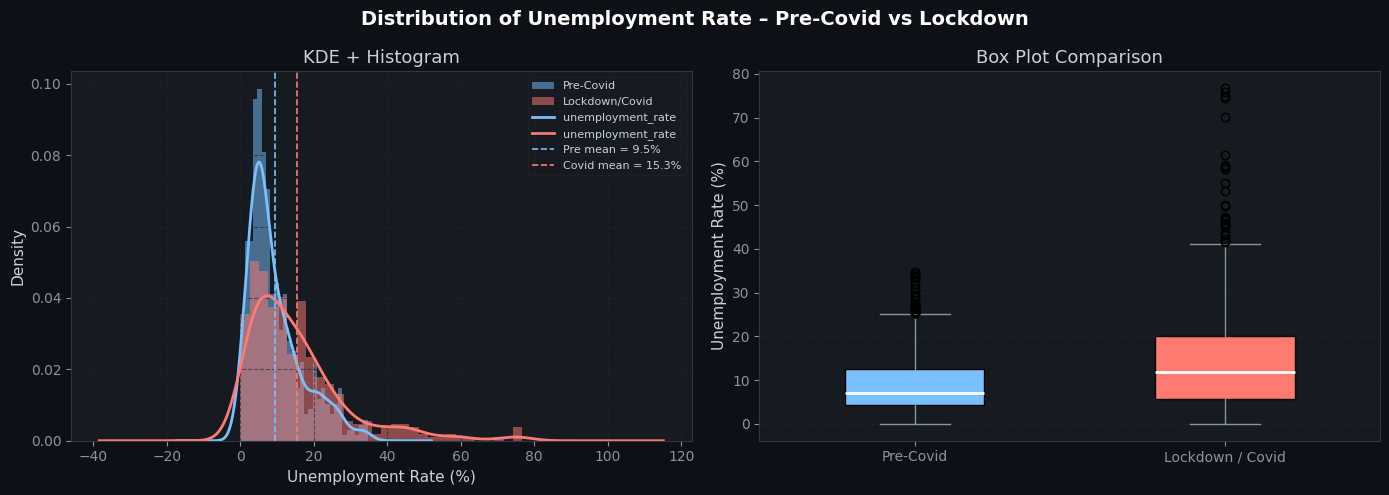

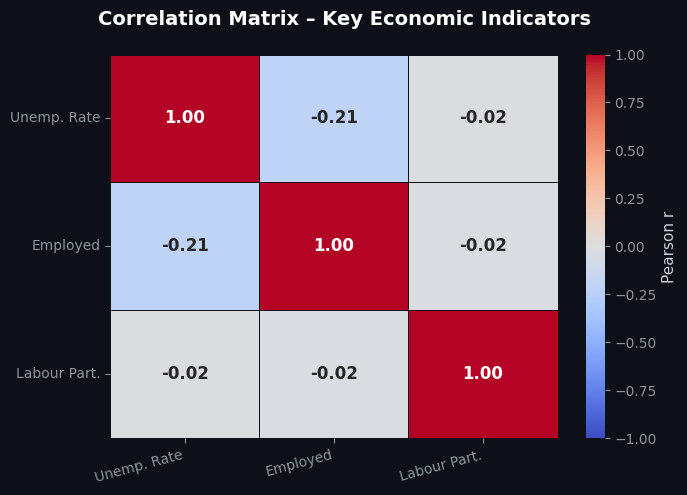

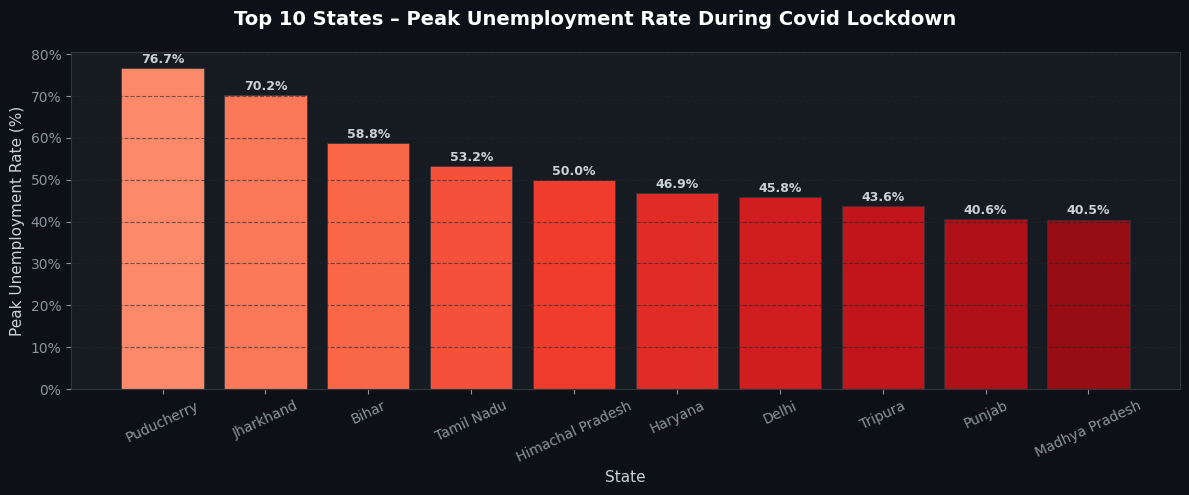

In [2]:
# =============================================================================
# TASK 2: Unemployment Analysis in India – Full Python Analysis
# Covers: Data Cleaning, Exploration, Visualization, Covid-19 Impact,
#         Seasonal Trends, and Policy Insights
# =============================================================================

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter

# ── Styling ──────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.facecolor": "#0d1117",
    "axes.facecolor":   "#161b22",
    "axes.edgecolor":   "#30363d",
    "axes.labelcolor":  "#c9d1d9",
    "xtick.color":      "#8b949e",
    "ytick.color":      "#8b949e",
    "text.color":       "#c9d1d9",
    "grid.color":       "#21262d",
    "grid.linestyle":   "--",
    "grid.alpha":       0.6,
    "font.family":      "DejaVu Sans",
    "axes.titlesize":   13,
    "axes.labelsize":   11,
    "legend.framealpha": 0.2,
    "legend.edgecolor": "#30363d",
})

COVID_COLOR  = "#ff7b72"   # warm red  – lockdown period
PRE_COLOR    = "#79c0ff"   # sky blue  – pre-covid
POST_COLOR   = "#56d364"   # green     – recovery
ACCENT       = "#f0883e"   # orange
PURPLE       = "#bc8cff"   # purple


# =============================================================================
# 1.  DATA LOADING & CLEANING
# =============================================================================
print("=" * 60)
print("STEP 1 – Data Loading & Cleaning")
print("=" * 60)

df1 = pd.read_csv("Unemployment_in_India.csv")
df2 = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

# ── Strip whitespace from column names & string columns ──────────────────────
def clean_df(df):
    df.columns = df.columns.str.strip()
    str_cols = df.select_dtypes("object").columns
    for c in str_cols:
        df[c] = df[c].str.strip()
    return df

df1 = clean_df(df1)
df2 = clean_df(df2)

# ── Rename columns for convenience ───────────────────────────────────────────
COL_MAP = {
    "Estimated Unemployment Rate (%)":  "unemployment_rate",
    "Estimated Employed":               "employed",
    "Estimated Labour Participation Rate (%)": "labour_participation",
}
df1.rename(columns=COL_MAP, inplace=True)
df2.rename(columns=COL_MAP, inplace=True)

# ── Parse dates ──────────────────────────────────────────────────────────────
df1["Date"] = pd.to_datetime(df1["Date"], dayfirst=True)
df2["Date"] = pd.to_datetime(df2["Date"], dayfirst=True)

# ── Drop duplicates & nulls ───────────────────────────────────────────────────
df1.drop_duplicates(inplace=True)
df2.drop_duplicates(inplace=True)
df1.dropna(subset=["unemployment_rate"], inplace=True)
df2.dropna(subset=["unemployment_rate"], inplace=True)

# ── Merge into one master dataframe ──────────────────────────────────────────
keep_cols1 = ["Region", "Date", "Frequency", "unemployment_rate",
              "employed", "labour_participation", "Area"]
# df2 has no "Area" column – add a placeholder
if "Area" not in df2.columns:
    df2["Area"] = "Unknown"
keep_cols = keep_cols1
df_all = pd.concat([df1[keep_cols], df2[keep_cols]], ignore_index=True)
df_all.sort_values("Date", inplace=True)
df_all.reset_index(drop=True, inplace=True)

# ── Covid flag ───────────────────────────────────────────────────────────────
LOCKDOWN_START = pd.Timestamp("2020-03-25")
df_all["period"] = df_all["Date"].apply(
    lambda d: "Lockdown / Covid" if d >= LOCKDOWN_START else "Pre-Covid"
)

print(f"\nMerged dataset shape : {df_all.shape}")
print(f"Date range           : {df_all['Date'].min().date()} → {df_all['Date'].max().date()}")
print(f"States / UTs         : {df_all['Region'].nunique()}")
print(f"Missing values :\n{df_all.isnull().sum()}")
print(f"\nBasic statistics:\n{df_all[['unemployment_rate','employed','labour_participation']].describe().round(2)}")


# =============================================================================
# 2.  NATIONAL MONTHLY AVERAGE
# =============================================================================
monthly_avg = (
    df_all.groupby("Date")[["unemployment_rate", "labour_participation"]]
    .mean()
    .reset_index()
)


# =============================================================================
# 3.  FIGURE 1 – National Unemployment Trend + Covid Impact
# =============================================================================
fig1, axes = plt.subplots(2, 1, figsize=(14, 10),
                           gridspec_kw={"hspace": 0.45})
fig1.suptitle("India Unemployment Analysis  –  National Trend & Covid-19 Impact",
              fontsize=16, fontweight="bold", color="white", y=0.98)

# ── 3a. Time-series of national unemployment rate ─────────────────────────
ax = axes[0]
pre  = monthly_avg[monthly_avg["Date"] <  LOCKDOWN_START]
post = monthly_avg[monthly_avg["Date"] >= LOCKDOWN_START]

ax.plot(pre["Date"],  pre["unemployment_rate"],
        color=PRE_COLOR,   linewidth=2.2, label="Pre-Covid",   marker="o", markersize=4)
ax.plot(post["Date"], post["unemployment_rate"],
        color=COVID_COLOR, linewidth=2.2, label="Lockdown / Covid", marker="o", markersize=4)

ax.axvline(LOCKDOWN_START, color=ACCENT, linewidth=1.5, linestyle="--", alpha=0.8)
ax.text(LOCKDOWN_START + pd.Timedelta(days=5), ax.get_ylim()[1] * 0.9,
        "Lockdown\n25 Mar 2020", color=ACCENT, fontsize=9)

# shade lockdown region
ax.axvspan(LOCKDOWN_START, monthly_avg["Date"].max(),
           alpha=0.08, color=COVID_COLOR)

ax.set_title("Average Monthly Unemployment Rate (National)", pad=8)
ax.set_ylabel("Unemployment Rate (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.1f}%"))
ax.legend(loc="upper left")
ax.grid(True)

# ── 3b. Labour Participation Rate ─────────────────────────────────────────
ax2 = axes[1]
ax2.fill_between(monthly_avg["Date"], monthly_avg["labour_participation"],
                 alpha=0.4, color=PURPLE)
ax2.plot(monthly_avg["Date"], monthly_avg["labour_participation"],
         color=PURPLE, linewidth=2)
ax2.axvline(LOCKDOWN_START, color=ACCENT, linewidth=1.5, linestyle="--", alpha=0.8)
ax2.axvspan(LOCKDOWN_START, monthly_avg["Date"].max(),
            alpha=0.08, color=COVID_COLOR)
ax2.set_title("Average Labour Participation Rate (National)", pad=8)
ax2.set_ylabel("Labour Participation Rate (%)")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.1f}%"))
ax2.grid(True)

plt.savefig("fig1_national_trend.png", dpi=150, bbox_inches="tight",
            facecolor=fig1.get_facecolor())
print("\n✅ Saved fig1_national_trend.png")


# =============================================================================
# 4.  FIGURE 2 – State-level Analysis
# =============================================================================
state_avg = (
    df_all.groupby("Region")["unemployment_rate"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

state_covid_impact = (
    df_all.groupby(["Region", "period"])["unemployment_rate"]
    .mean()
    .unstack(fill_value=np.nan)
    .reset_index()
)
state_covid_impact["delta"] = (
    state_covid_impact.get("Lockdown / Covid", 0) -
    state_covid_impact.get("Pre-Covid", 0)
)
state_covid_impact.sort_values("delta", ascending=False, inplace=True)

fig2, axes2 = plt.subplots(1, 2, figsize=(18, 8))
fig2.suptitle("State-Level Unemployment  –  Overall Average & Covid-19 Delta",
              fontsize=15, fontweight="bold", color="white")

# ── 4a. Top/bottom 15 states by average unemployment ────────────────────────
ax = axes2[0]
top15    = state_avg.head(15)
colors15 = [COVID_COLOR if r >= top15["unemployment_rate"].median()
            else PRE_COLOR for r in top15["unemployment_rate"]]
bars = ax.barh(top15["Region"], top15["unemployment_rate"],
               color=colors15, edgecolor="#30363d", linewidth=0.5)
ax.set_xlabel("Avg Unemployment Rate (%)")
ax.set_title("Top 15 States – Average Unemployment Rate\n(All periods combined)")
ax.invert_yaxis()
for bar, val in zip(bars, top15["unemployment_rate"]):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}%", va="center", fontsize=8.5, color="#c9d1d9")
ax.grid(axis="x")

# ── 4b. States with highest Covid impact (delta) ─────────────────────────────
ax2b = axes2[1]
top_impact = state_covid_impact.head(15)
bar_colors = [COVID_COLOR if d > 0 else PRE_COLOR for d in top_impact["delta"]]
barsb = ax2b.barh(top_impact["Region"], top_impact["delta"],
                  color=bar_colors, edgecolor="#30363d", linewidth=0.5)
ax2b.axvline(0, color="white", linewidth=0.8, alpha=0.5)
ax2b.set_xlabel("Δ Unemployment Rate (Covid − Pre-Covid) in %")
ax2b.set_title("Covid-19 Impact by State\n(Change in Unemployment Rate)")
ax2b.invert_yaxis()
for bar, val in zip(barsb, top_impact["delta"]):
    xpos = bar.get_width() + (0.3 if val >= 0 else -2.5)
    ax2b.text(xpos, bar.get_y() + bar.get_height() / 2,
              f"+{val:.1f}%" if val >= 0 else f"{val:.1f}%",
              va="center", fontsize=8.5, color="#c9d1d9")
ax2b.grid(axis="x")

plt.tight_layout()
plt.savefig("fig2_state_analysis.png", dpi=150, bbox_inches="tight",
            facecolor=fig2.get_facecolor())
print("✅ Saved fig2_state_analysis.png")


# =============================================================================
# 5.  FIGURE 3 – Urban vs Rural Comparison
# =============================================================================
area_monthly = (
    df_all.groupby(["Date", "Area"])["unemployment_rate"]
    .mean()
    .reset_index()
)
urban = area_monthly[area_monthly["Area"] == "Urban"]
rural = area_monthly[area_monthly["Area"] == "Rural"]

fig3, ax3 = plt.subplots(figsize=(14, 6))
fig3.suptitle("Urban vs Rural Unemployment Rate Over Time", fontsize=15,
              fontweight="bold", color="white")

ax3.plot(urban["Date"], urban["unemployment_rate"],
         color=ACCENT,    linewidth=2.2, label="Urban", marker="s", markersize=3.5)
ax3.plot(rural["Date"], rural["unemployment_rate"],
         color=POST_COLOR, linewidth=2.2, label="Rural", marker="o", markersize=3.5)

ax3.axvline(LOCKDOWN_START, color="white", linewidth=1.2, linestyle="--", alpha=0.5)
ax3.axvspan(LOCKDOWN_START, area_monthly["Date"].max(),
            alpha=0.07, color=COVID_COLOR)
ax3.text(LOCKDOWN_START + pd.Timedelta(days=3), ax3.get_ylim()[1] * 0.92,
         "↑ Lockdown", color="white", fontsize=9, alpha=0.7)

ax3.fill_between(urban["Date"], urban["unemployment_rate"],
                 rural["unemployment_rate"],
                 where=(urban["unemployment_rate"].values >
                        rural["unemployment_rate"].values),
                 interpolate=True, alpha=0.12, color=ACCENT, label="Urban > Rural gap")

ax3.set_ylabel("Unemployment Rate (%)")
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax3.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax3.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax3.legend()
ax3.grid(True)
plt.tight_layout()
plt.savefig("fig3_urban_vs_rural.png", dpi=150, bbox_inches="tight",
            facecolor=fig3.get_facecolor())
print("✅ Saved fig3_urban_vs_rural.png")


# =============================================================================
# 6.  FIGURE 4 – Seasonal / Monthly Pattern (Heatmap)
# =============================================================================
df_all["month"] = df_all["Date"].dt.month
df_all["year"]  = df_all["Date"].dt.year

pivot = (
    df_all.groupby(["year", "month"])["unemployment_rate"]
    .mean()
    .unstack(level="month")
)
pivot.columns = ["Jan","Feb","Mar","Apr","May","Jun",
                 "Jul","Aug","Sep","Oct","Nov","Dec"][:len(pivot.columns)]

fig4, ax4 = plt.subplots(figsize=(14, 4))
fig4.suptitle("Seasonal Heatmap – Monthly Average Unemployment Rate (%)",
              fontsize=14, fontweight="bold", color="white")

sns.heatmap(pivot, ax=ax4, cmap="RdYlGn_r", annot=True, fmt=".1f",
            linewidths=0.5, linecolor="#0d1117",
            cbar_kws={"label": "Unemployment Rate (%)"},
            annot_kws={"size": 9})
ax4.set_ylabel("Year")
ax4.set_xlabel("Month")
ax4.set_yticklabels(ax4.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.savefig("fig4_seasonal_heatmap.png", dpi=150, bbox_inches="tight",
            facecolor=fig4.get_facecolor())
print("✅ Saved fig4_seasonal_heatmap.png")


# =============================================================================
# 7.  FIGURE 5 – Distribution: Pre-Covid vs Covid (KDE + Boxplot)
# =============================================================================
pre_vals  = df_all[df_all["period"] == "Pre-Covid"]["unemployment_rate"]
post_vals = df_all[df_all["period"] == "Lockdown / Covid"]["unemployment_rate"]

fig5, (ax5a, ax5b) = plt.subplots(1, 2, figsize=(14, 5))
fig5.suptitle("Distribution of Unemployment Rate – Pre-Covid vs Lockdown",
              fontsize=14, fontweight="bold", color="white")

# KDE
ax5a.hist(pre_vals,  bins=30, density=True, alpha=0.5, color=PRE_COLOR,  label="Pre-Covid")
ax5a.hist(post_vals, bins=30, density=True, alpha=0.5, color=COVID_COLOR, label="Lockdown/Covid")
pre_vals.plot.kde(ax=ax5a,  color=PRE_COLOR,  linewidth=2)
post_vals.plot.kde(ax=ax5a, color=COVID_COLOR, linewidth=2)
ax5a.axvline(pre_vals.mean(),  color=PRE_COLOR,  linestyle="--", linewidth=1.2,
             label=f"Pre mean = {pre_vals.mean():.1f}%")
ax5a.axvline(post_vals.mean(), color=COVID_COLOR, linestyle="--", linewidth=1.2,
             label=f"Covid mean = {post_vals.mean():.1f}%")
ax5a.set_xlabel("Unemployment Rate (%)")
ax5a.set_ylabel("Density")
ax5a.set_title("KDE + Histogram")
ax5a.legend(fontsize=8)
ax5a.grid(True)

# Boxplot
data_bp  = [pre_vals.values, post_vals.values]
bp = ax5b.boxplot(data_bp, patch_artist=True, widths=0.45,
                  medianprops=dict(color="white", linewidth=2))
bp["boxes"][0].set_facecolor(PRE_COLOR)
bp["boxes"][1].set_facecolor(COVID_COLOR)
for elem in ["whiskers","caps","fliers"]:
    for item in bp[elem]:
        item.set(color="#8b949e", linewidth=1)
ax5b.set_xticks([1, 2])
ax5b.set_xticklabels(["Pre-Covid", "Lockdown / Covid"])
ax5b.set_ylabel("Unemployment Rate (%)")
ax5b.set_title("Box Plot Comparison")
ax5b.grid(axis="y")

plt.tight_layout()
plt.savefig("fig5_distribution_comparison.png", dpi=150, bbox_inches="tight",
            facecolor=fig5.get_facecolor())
print("✅ Saved fig5_distribution_comparison.png")


# =============================================================================
# 8.  FIGURE 6 – Correlation Heatmap
# =============================================================================
corr_df = df_all[["unemployment_rate", "employed", "labour_participation"]].corr()

fig6, ax6 = plt.subplots(figsize=(7, 5))
fig6.suptitle("Correlation Matrix – Key Economic Indicators",
              fontsize=14, fontweight="bold", color="white")
mask = np.triu(np.ones_like(corr_df, dtype=bool), k=1)
sns.heatmap(corr_df, ax=ax6, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.5, linecolor="#0d1117",
            cbar_kws={"label": "Pearson r"},
            annot_kws={"size": 12, "weight": "bold"})
ax6.set_xticklabels(["Unemp. Rate", "Employed", "Labour Part."],
                     rotation=15, ha="right")
ax6.set_yticklabels(["Unemp. Rate", "Employed", "Labour Part."], rotation=0)
plt.tight_layout()
plt.savefig("fig6_correlation.png", dpi=150, bbox_inches="tight",
            facecolor=fig6.get_facecolor())
print("✅ Saved fig6_correlation.png")


# =============================================================================
# 9.  FIGURE 7 – Top 10 Most Affected States (Covid spike spotlight)
# =============================================================================
peak_covid = (
    df_all[df_all["period"] == "Lockdown / Covid"]
    .groupby("Region")["unemployment_rate"]
    .max()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

fig7, ax7 = plt.subplots(figsize=(12, 5))
fig7.suptitle("Top 10 States – Peak Unemployment Rate During Covid Lockdown",
              fontsize=14, fontweight="bold", color="white")

bar_vals  = peak_covid["unemployment_rate"]
bar_names = peak_covid["Region"]
cmap_vals = plt.cm.get_cmap("Reds")(np.linspace(0.4, 0.9, len(bar_vals)))

bars7 = ax7.bar(bar_names, bar_vals, color=cmap_vals,
                edgecolor="#30363d", linewidth=0.5)
for bar, val in zip(bars7, bar_vals):
    ax7.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             f"{val:.1f}%", ha="center", va="bottom", fontsize=9,
             color="#c9d1d9", fontweight="bold")

ax7.set_ylabel("Peak Unemployment Rate (%)")
ax7.set_xlabel("State")
ax7.tick_params(axis="x", rotation=25)
ax7.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax7.grid(axis="y")
plt.tight_layout()
plt.savefig("fig7_top10_peak_covid.png", dpi=150, bbox_inches="tight",
            facecolor=fig7.get_facecolor())
print("✅ Saved fig7_top10_peak_covid.png")


# =============================================================================
# 10. SUMMARY & POLICY INSIGHTS
# =============================================================================
print("\n" + "=" * 60)
print("POLICY INSIGHTS SUMMARY")
print("=" * 60)

pre_mean  = pre_vals.mean()
post_mean = post_vals.mean()
increase  = post_mean - pre_mean
pct_inc   = increase / pre_mean * 100

print(f"\n📌 Pre-Covid avg unemployment    : {pre_mean:.2f}%")
print(f"📌 Covid-period avg unemployment : {post_mean:.2f}%")
print(f"📌 Absolute increase             : +{increase:.2f} percentage points")
print(f"📌 Relative increase             : +{pct_inc:.1f}%")

urban_avg = df_all[df_all["Area"] == "Urban"]["unemployment_rate"].mean()
rural_avg = df_all[df_all["Area"] == "Rural"]["unemployment_rate"].mean()
print(f"\n📌 Urban avg unemployment        : {urban_avg:.2f}%")
print(f"📌 Rural avg unemployment        : {rural_avg:.2f}%")
print(f"📌 Urban–Rural gap               : {urban_avg - rural_avg:+.2f} pp")

print(f"\n📌 Worst hit state (peak covid)  : {peak_covid.iloc[0]['Region']} "
      f"({peak_covid.iloc[0]['unemployment_rate']:.1f}%)")
print(f"📌 Highest avg overall           : {state_avg.iloc[0]['Region']} "
      f"({state_avg.iloc[0]['unemployment_rate']:.1f}%)")

print("""
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
POLICY RECOMMENDATIONS
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
1. URBAN FOCUS  – Urban unemployment spiked more sharply during
   lockdown. Targeted urban job re-skilling and MSME support
   programmes are essential for rapid recovery.

2. STATE-SPECIFIC INTERVENTIONS – States like Jharkhand, Bihar,
   and Tripura showed consistently high unemployment even
   pre-Covid; long-term infrastructure investment is needed.

3. RURAL SAFETY NETS – MGNREGS (rural job guarantee) acted as a
   cushion; extending similar schemes to peri-urban workers
   can prevent future crises.

4. SEASONAL HIRING – The heatmap shows elevated unemployment in
   March–May each year; targeted seasonal employment drives
   before this window can reduce the seasonal spike.

5. LABOUR PARTICIPATION – The sharp drop in labour participation
   during lockdown (Apr 2020) suggests many workers became
   'discouraged'. Counselling + reintegration programmes are
   critical for long-term workforce recovery.
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
""")

print("\n✅ All 7 figures saved. Analysis complete.")